<a href="https://colab.research.google.com/github/d03antony-ai/labo-momentum/blob/main/deep_momentum_alpaca_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Momentum Network · Alpaca

Mise en pratique de l'article **Lim, Zohren & Roberts (2019), *Enhancing Time Series Momentum Strategies Using Deep Neural Networks***.

Le notebook suit l'ordre de l'article.
1. Données journalières d'ETF via **Alpaca**
2. Variables d'entrée de l'article (rendements normalisés + MACD)
3. Stratégies de référence · Buy & hold, Moskowitz 2012, Baz 2015
4. **LSTM à sorties directes** entraîné en maximisant le **ratio de Sharpe** (équations 14 et 16)
5. Backtest hors échantillon
6. Envoi des positions sur le compte **paper trading** Alpaca (argent fictif)

> Projet pédagogique. Ce n'est pas un conseil en investissement. Le compte utilisé est un compte de démonstration.

## 0 · Clés Alpaca (une seule fois)

1. Créez un compte sur [alpaca.markets](https://alpaca.markets) et ouvrez l'espace **Paper Trading**.
2. Générez une clé API (**API Key** et **Secret Key**).
3. Dans Colab, cliquez sur l'icône 🔑 **Secrets** à gauche et ajoutez
   - `ALPACA_API_KEY`
   - `ALPACA_SECRET_KEY`
4. Activez l'accès au notebook pour les deux.

Si les Secrets ne sont pas trouvés, le notebook vous demandera simplement de coller les clés dans une case, au moment du téléchargement des données.

Les clés ne sont jamais écrites dans le notebook, ce qui permet de le publier sur GitHub sans risque.

In [1]:
!pip install -q alpaca-py

## 1 · Paramètres

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

# Univers d'ETF liquides couvrant plusieurs classes d'actifs
# (Alpaca ne propose pas de futures, on utilise des ETF équivalents)
UNIVERS = ["SPY", "QQQ", "IWM", "EFA", "EEM",      # actions
           "TLT", "IEF", "LQD", "HYG",             # obligations
           "GLD", "SLV", "USO", "DBA",             # matières premières
           "UUP", "FXE", "FXY"]                     # devises

DEBUT       = "2016-01-01"
DEBUT_TEST  = "2023-01-01"   # tout ce qui précède sert à l'entraînement
DEMO        = False          # True = prix simulés, pour tester sans clés

VOL_CIBLE   = 0.15           # volatilité annuelle visée par actif (article)
LEVIER_MAX  = 3.0
COUT_BP     = 2              # coût de transaction, en points de base
FENETRE     = 63             # longueur des séquences LSTM (~ 1 trimestre)
ECHELLES    = [(8, 24), (16, 48), (32, 96)]

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)

# Clés Alpaca · essaie les Secrets de Colab, sinon les demande à l'écran
from getpass import getpass
_cles = {}
def cle(nom):
    if nom not in _cles:
        try:
            from google.colab import userdata
            _cles[nom] = userdata.get(nom)
        except Exception:
            _cles[nom] = getpass(f"Collez votre {nom} puis appuyez sur Entrée : ").strip()
    return _cles[nom]

## 2 · Données

In [3]:
def prix_demo():
    rng = np.random.default_rng(SEED)
    dates = pd.bdate_range(DEBUT, pd.Timestamp.today().normalize())
    df = {}
    for s in UNIVERS:
        tendance = np.cumsum(rng.normal(0, 0.0003, len(dates)))
        r = rng.normal(0, 0.01, len(dates)) + 0.02 * tendance
        df[s] = 100 * np.exp(np.cumsum(r))
    return pd.DataFrame(df, index=dates)

def prix_alpaca():
    from alpaca.data.historical import StockHistoricalDataClient
    from alpaca.data.requests import StockBarsRequest
    from alpaca.data.timeframe import TimeFrame
    from alpaca.data.enums import Adjustment, DataFeed

    client = StockHistoricalDataClient(cle("ALPACA_API_KEY"), cle("ALPACA_SECRET_KEY"))
    fin = pd.Timestamp.now(tz="UTC") - pd.Timedelta(days=1)  # données gratuites = différé
    bars = None
    for feed in (DataFeed.SIP, DataFeed.IEX):
        try:
            req = StockBarsRequest(symbol_or_symbols=UNIVERS, timeframe=TimeFrame.Day,
                                   start=pd.Timestamp(DEBUT, tz="UTC"), end=fin,
                                   adjustment=Adjustment.ALL, feed=feed)
            bars = client.get_stock_bars(req).df
            print("Flux utilisé :", feed.value)
            break
        except Exception as e:
            print(f"Flux {feed.value} refusé : {e}")
    if bars is None:
        raise RuntimeError("Impossible de récupérer les prix. Vérifiez vos clés Alpaca (compte Paper).")
    prix = bars["close"].unstack(level=0)
    prix.index = prix.index.tz_convert("America/New_York").tz_localize(None).normalize()
    return prix[UNIVERS].sort_index()

prix = prix_demo() if DEMO else prix_alpaca()
prix = prix.ffill().dropna(how="all")
print(prix.shape, prix.index[0].date(), "→", prix.index[-1].date())
prix.tail()

Collez votre ALPACA_API_KEY puis appuyez sur Entrée : ··········
Collez votre ALPACA_SECRET_KEY puis appuyez sur Entrée : ··········
Flux utilisé : sip
(2738, 16) 2016-01-04 → 2026-11-20


symbol,SPY,QQQ,IWM,EFA,EEM,TLT,IEF,LQD,HYG,GLD,SLV,USO,DBA,UUP,FXE,FXY
timestamp,,,,,,,,,,,,,,,,
2026-11-16,739.95,661.75,272.94,102.64,58.89,79.38,90.24,102.80,76.73,352.93,42.39,140.03,26.39,29.56,101.48,57.46
2026-11-17,732.44,656.95,269.05,101.35,58.27,79.55,90.41,102.74,76.63,352.48,42.64,140.24,26.38,29.54,101.58,57.50
2026-11-18,730.20,659.51,270.12,100.26,57.88,80.22,90.67,103.15,76.65,341.19,40.70,136.11,26.02,29.62,101.33,57.51
2026-11-19,715.87,645.04,264.22,98.78,56.75,80.35,90.82,103.08,76.53,335.18,39.64,138.09,26.21,29.63,101.30,57.38
2026-11-20,689.81,608.45,256.61,96.14,53.84,81.45,91.65,103.69,76.33,322.87,36.97,139.63,26.15,29.62,101.21,57.84


## 3 · Variables d'entrée (section III de l'article)

Pour chaque actif et chaque jour
- **Rendements normalisés** sur 1 jour, 1, 3, 6 et 12 mois, divisés par la volatilité × √durée
- **Indicateurs MACD** de Baz pour les trois couples (S, L), équations 4 à 6
- **Cible** · rendement du lendemain mis à l'échelle de la volatilité cible, σ_tgt/σ_t × r_{t+1}

In [4]:
rend = prix.pct_change()
vol_j = rend.ewm(span=60, min_periods=60).std()          # volatilité journalière ex ante
vol_an = vol_j * np.sqrt(252)
echelle = (VOL_CIBLE / vol_an).clip(upper=LEVIER_MAX)    # mise à l'échelle de la position

def macd_Y(p, S, L):
    m = lambda n: p.ewm(alpha=1 / n, adjust=False).mean()
    q = (m(S) - m(L)) / p.rolling(63).std()               # (5)-(6)
    return q / q.rolling(252).std()                       # (4)

def phi(y):
    return y * np.exp(-y ** 2 / 4) / 0.89

features = {}
for k in [1, 21, 63, 126, 252]:
    features[f"r{k}"] = (prix.pct_change(k) / (vol_j * np.sqrt(k))).clip(-5, 5)
for S, L in ECHELLES:
    features[f"macd{S}_{L}"] = macd_Y(prix, S, L).clip(-5, 5)
NOMS = list(features)

cible = (rend.shift(-1) * echelle).clip(-0.2, 0.2)       # rendement capté si position = 1
print("Variables :", NOMS)

Variables : ['r1', 'r21', 'r63', 'r126', 'r252', 'macd8_24', 'macd16_48', 'macd32_96']


## 4 · Stratégies de référence

- **Buy & hold** · position = 1
- **Moskowitz 2012** · position = signe du rendement sur 252 jours
- **Baz 2015** · moyenne de φ(Y) sur les trois horizons MACD

In [5]:
positions = {
    "Buy & hold": pd.DataFrame(1.0, index=prix.index, columns=UNIVERS),
    "Moskowitz": np.sign(prix.pct_change(252)),
    "Baz MACD": sum(phi(features[f"macd{S}_{L}"]) for S, L in ECHELLES) / len(ECHELLES),
}

## 5 · Deep Momentum Network (LSTM + perte Sharpe)

- Le réseau lit les 63 derniers jours de variables et sort directement une **position entre −1 et +1** (tanh), équation 14.
- On l'entraîne en **minimisant −Sharpe** des rendements captés, équation 16.
- Un seul modèle est appris sur tous les actifs à la fois, comme dans l'article.

train (864, 63, 8) | validation (160, 63, 8)


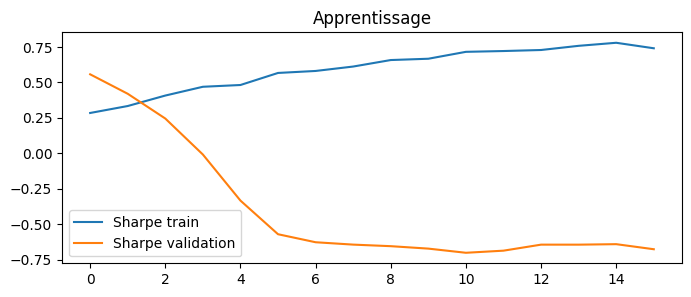

In [6]:
def sequences(debut, fin, pas):
    X, Y = [], []
    for s in UNIVERS:
        F = pd.concat([features[n][s] for n in NOMS], axis=1).loc[debut:fin]
        y = cible[s].loc[debut:fin]
        ok = F.notna().all(axis=1) & y.notna()
        F, y = F[ok].values, y[ok].values
        for i in range(0, len(F) - FENETRE + 1, pas):
            X.append(F[i:i + FENETRE]); Y.append(y[i:i + FENETRE])
    return np.array(X, "float32"), np.array(Y, "float32")[..., None]

dates_train = prix.loc[:DEBUT_TEST].index[:-1]
coupure = dates_train[int(len(dates_train) * 0.85)]       # 15 % finaux = validation
X_tr, Y_tr = sequences(dates_train[0], coupure, pas=FENETRE // 3)
X_va, Y_va = sequences(coupure, dates_train[-1], pas=FENETRE // 3)
print("train", X_tr.shape, "| validation", X_va.shape)

def perte_sharpe(y_vrai, position):
    R = y_vrai * position                                 # rendement capté (15)
    moy = tf.reduce_mean(R)
    var = tf.reduce_mean(tf.square(R)) - tf.square(moy)
    return -moy * np.sqrt(252) / tf.sqrt(var + 1e-9)      # −Sharpe annualisé (16)

def construire(n_caches=16, dropout=0.3, lr=1e-3):
    inp = keras.Input(shape=(None, len(NOMS)))
    x = keras.layers.LSTM(n_caches, return_sequences=True, dropout=dropout)(inp)
    out = keras.layers.Dense(1, activation="tanh")(x)
    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(lr, clipnorm=1.0), loss=perte_sharpe)
    return m

modele = construire()
hist = modele.fit(X_tr, Y_tr, validation_data=(X_va, Y_va),
                  epochs=100, batch_size=64, verbose=0,
                  callbacks=[keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True)])

plt.figure(figsize=(8, 3))
plt.plot(-np.array(hist.history["loss"]), label="Sharpe train")
plt.plot(-np.array(hist.history["val_loss"]), label="Sharpe validation")
plt.legend(); plt.title("Apprentissage"); plt.show()

In [7]:
def positions_lstm(modele):
    out = pd.DataFrame(np.nan, index=prix.index, columns=UNIVERS)
    for s in UNIVERS:
        F = pd.concat([features[n][s] for n in NOMS], axis=1).dropna()
        if len(F) < FENETRE:
            continue
        fen = np.lib.stride_tricks.sliding_window_view(F.values, (FENETRE, len(NOMS)))[:, 0]
        pred = modele.predict(fen.astype("float32"), batch_size=512, verbose=0)[:, -1, 0]
        out.loc[F.index[FENETRE - 1:], s] = pred
    return out

positions["Deep Momentum LSTM"] = positions_lstm(modele)

## 6 · Backtest hors échantillon

,Rendement an.,Volatilité,Sharpe,Sortino,Perte max,% jours gagnants
Buy & hold,9.5%,7.7%,1.23,1.79,-7.5%,54.5%
Moskowitz,3.4%,6.2%,0.54,0.74,-7.3%,54.3%
Baz MACD,1.3%,3.9%,0.33,0.48,-5.4%,53.4%
Deep Momentum LSTM,2.1%,3.6%,0.58,0.79,-4.5%,52.9%


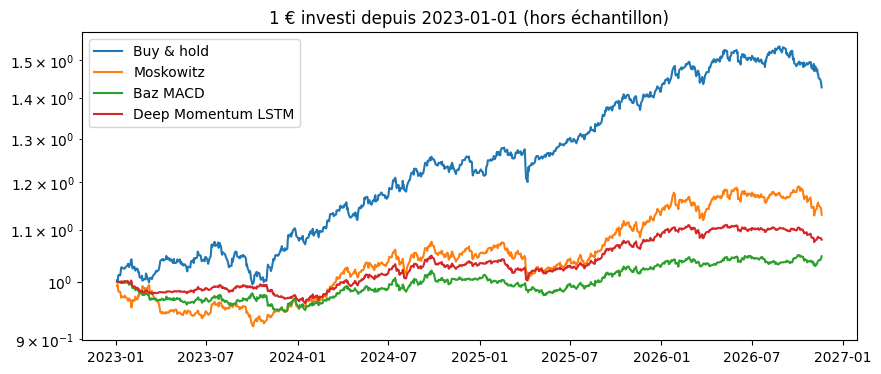

In [8]:
def backtest(pos):
    expo = pos * echelle                                   # position × σ_tgt/σ_t
    brut = expo * rend.shift(-1)
    couts = expo.diff().abs() * COUT_BP / 1e4
    return (brut - couts).loc[DEBUT_TEST:].mean(axis=1).dropna()   # portefeuille équipondéré

def stats(r):
    cum = (1 + r).cumprod()
    an, vol = r.mean() * 252, r.std() * np.sqrt(252)
    neg = r[r < 0].std() * np.sqrt(252)
    return pd.Series({"Rendement an.": an, "Volatilité": vol, "Sharpe": an / vol,
                      "Sortino": an / neg, "Perte max": (cum / cum.cummax() - 1).min(),
                      "% jours gagnants": (r > 0).mean()})

res = {k: backtest(v) for k, v in positions.items()}
tableau = pd.DataFrame({k: stats(v) for k, v in res.items()}).T
display(tableau.style.format({"Rendement an.": "{:.1%}", "Volatilité": "{:.1%}", "Sharpe": "{:.2f}",
                              "Sortino": "{:.2f}", "Perte max": "{:.1%}", "% jours gagnants": "{:.1%}"}))

plt.figure(figsize=(10, 4))
for k, r in res.items():
    plt.plot((1 + r).cumprod(), label=k)
plt.yscale("log"); plt.legend(); plt.title(f"1 € investi depuis {DEBUT_TEST} (hors échantillon)")
plt.show()

### Lire les résultats honnêtement
- Une seule période de test ne prouve rien. Changez `DEBUT_TEST` et `SEED` pour vérifier que le classement tient.
- Avec 16 ETF et quelques années, le LSTM a peu de données. L'article utilisait 88 contrats futures sur 25 ans.
- Un Sharpe hors échantillon au-dessus de 1 sur ETF serait déjà remarquable. S'il est très élevé, cherchez d'abord une erreur.

## 7 · Paper trading Alpaca

Calcule la position du jour pour chaque ETF puis passe les ordres sur le compte **fictif**.
Laissez `DRY_RUN = True` pour seulement afficher les ordres.

In [9]:
DRY_RUN          = True    # False pour envoyer réellement les ordres (compte paper)
FRACTION_CAPITAL = 0.5     # part du capital fictif utilisée
VENTE_A_DECOUVERT = True   # False = positions négatives ramenées à 0
MIN_ORDRE_USD    = 200     # ignore les petits ajustements

pos_jour = positions["Deep Momentum LSTM"].iloc[-1]
poids = (pos_jour * echelle.iloc[-1]).fillna(0) / len(UNIVERS)
if not VENTE_A_DECOUVERT:
    poids = poids.clip(lower=0)
dernier_prix = prix.iloc[-1]

cibles = pd.DataFrame({"position modèle": pos_jour.round(2), "poids portefeuille": poids.round(3),
                       "prix": dernier_prix.round(2)})
cibles

,position modèle,poids portefeuille,prix
SPY,0.65,0.030,689.81
QQQ,0.36,0.011,608.45
IWM,0.01,0.000,256.61
EFA,0.40,0.020,96.14
EEM,-0.02,-0.000,53.84
TLT,-0.45,-0.037,81.45
IEF,-0.32,-0.047,91.65
LQD,-0.30,-0.045,103.69
HYG,-0.27,-0.051,76.33
GLD,-0.35,-0.012,322.87


In [10]:
from alpaca.trading.client import TradingClient
from alpaca.trading.requests import MarketOrderRequest
from alpaca.trading.enums import OrderSide, TimeInForce

tc = TradingClient(cle("ALPACA_API_KEY"), cle("ALPACA_SECRET_KEY"), paper=True)
compte = tc.get_account()
capital = float(compte.equity) * FRACTION_CAPITAL
actuel = {p.symbol: float(p.qty) for p in tc.get_all_positions()}
print(f"Capital fictif utilisé : {capital:,.0f} $")

def ordre(symbole, qte):
    if qte == 0:
        return
    sens = OrderSide.BUY if qte > 0 else OrderSide.SELL
    print(f"{'[simulation] ' if DRY_RUN else ''}{sens.value:4s} {abs(qte):6.0f} {symbole}")
    if not DRY_RUN:
        tc.submit_order(MarketOrderRequest(symbol=symbole, qty=abs(qte), side=sens,
                                           time_in_force=TimeInForce.DAY))

for s in UNIVERS:
    cible_qte = int(poids[s] * capital / dernier_prix[s])   # arrondi vers 0, actions entières
    deja = actuel.get(s, 0.0)
    delta = cible_qte - deja
    if abs(delta) * dernier_prix[s] < MIN_ORDRE_USD:
        continue
    if deja * cible_qte < 0:          # Alpaca refuse de passer de long à short en un ordre
        ordre(s, -deja)
        ordre(s, cible_qte)
    else:
        ordre(s, delta)

Capital fictif utilisé : 50,000 $
[simulation] buy       2 SPY
[simulation] buy      10 EFA
[simulation] sell     22 TLT
[simulation] sell     25 IEF
[simulation] sell     21 LQD
[simulation] sell     33 HYG
[simulation] sell      1 GLD
[simulation] sell     14 SLV
[simulation] buy       5 USO
[simulation] sell     20 DBA
[simulation] buy     217 UUP
[simulation] sell     58 FXE
[simulation] sell      9 FXY


## 8 · Publier sur GitHub

**Méthode simple, depuis Colab**
1. Menu **Fichier → Enregistrer une copie dans GitHub**
2. Autorisez Colab à accéder à votre compte GitHub
3. Choisissez le dépôt (créez-le avant sur github.com, par exemple `deep-momentum-alpaca`), le nom du fichier et un message de commit

Les clés restent dans les Secrets de Colab, elles ne partent pas sur GitHub.

**Prochaine étape possible** · exécuter la section 7 automatiquement chaque jour avec GitHub Actions, en stockant les clés dans les *Secrets* du dépôt.